# Task 4 — Otimização, limiar de decisão e avaliação final

Este notebook faz a Task 4: escolher os modelos mais promissores da Task 3, otimizar os seus hiperparâmetros e perceber se a otimização traz uma melhoria real e estável; depois, escolher o limiar de decisão do modelo mais forte, avaliar o modelo final uma única vez no teste e interpretá-lo.

**Como funciona**

- Usa o `avaliar_folds` e a restante infraestrutura da Task 2 (`avaliacao.py`) e o pré-processamento da Task 3 (`ablacao.py`): 4 folds temporais, recall com 200 alertas por 1000 sessões como métrica principal. O pré-processamento e o modelo são **reajustados em cada fold, só com o treino desse fold**. O teste (out–dez/2021) é removido ao carregar os dados e nunca é usado aqui.
- As funções de pesquisa e de escolha estão em `otimizacao.py`. O notebook só chama essas funções e mostra os resultados.
- **Os resultados vão sendo guardados** em `Resultados/` durante a pesquisa. Se o computador adormecer ou o kernel falhar, volta-se a correr a mesma célula e só se calcula o que falta.

| Secção | O que responde |
|---|---|
| 0 | Configuração e dados |
| 1 | Que modelos otimizar, e porquê |
| 2 | Procedimento de pesquisa e espaços de pesquisa |
| 3 | As três pesquisas (logística, boosting, Random Forest) |
| 4 | Inicial contra otimizado: média, variabilidade e evolução no tempo |
| 5 | Verificação sem otimismo: escolher com F1–F3 e avaliar em F4 |
| 6 | Qual é o modelo probabilístico mais forte |
| 7 | Ficheiros guardados para o limiar e o modelo final |
| 8 | Conclusões: o que escrever no relatório |
| 9 | Limiar de decisão: critério, comparação com 0,5 e consequências (validação) |
| 10 | Calibração das probabilidades |

## 0. Configuração e dados

In [1]:
import json
import warnings
from pathlib import Path
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"   # põe o número de núcleos do teu computador
import numpy as np
import pandas as pd

import ablacao as ab
import otimizacao as ot
from avaliacao import avaliar_folds, comparar

warnings.filterwarnings("ignore", category=FutureWarning)   # os avisos de convergência continuam visíveis
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)

DATA_PATH = Path("Charging_Data_educational.csv")
PASTA = Path("Resultados")
PASTA.mkdir(exist_ok=True)

X_ALERTAS = 200      # orçamento de alertas por 1000 sessões (secção 8.4 do relatório)
SEED = 0             # semente da pesquisa aleatória
AMOSTRA = 1          # 1 = todos os dados. Para um ensaio rápido, 8 (volta a 1 para os resultados finais)
ESPACO = None        # sem informação espacial: com o histórico, o posto não acrescenta nada (secção 9.1 e 9.2)
GRUPOS_TODOS = ab.CONFIGURACOES["4 + histórico do utilizador"]
MODELOS = ["logistica", "boosting", "random_forest"]
NOMES = {"logistica": "Regressão logística", "boosting": "Boosting", "random_forest": "Random Forest"}

In [2]:
df = ab.carregar_dev(DATA_PATH)            # só treino e validação (dez/2019 – set/2021)
assert df["Start Time"].max() < pd.Timestamp("2021-10-01"), "o teste não pode estar carregado"
if AMOSTRA > 1:
    df = df.iloc[::AMOSTRA].reset_index(drop=True)
    print(f"ATENÇÃO: ensaio rápido com 1 em cada {AMOSTRA} sessões. Não usar estes resultados.")
print(f"{len(df):,} sessões | {df['Start Time'].min():%Y-%m-%d} a {df['Start Time'].max():%Y-%m-%d} | prevalência {df['is_Abnormal'].mean():.1%}")


def metricas_fold(res):
    return pd.Series({"recall@200 (média)": res["recall"].mean(), "desvio": res["recall"].std(ddof=1),
                      "pior fold": res["recall"].min(), "PR-AUC norm. (média)": res["pr_auc_norm"].mean(),
                      "ROC-AUC (média)": res["roc_auc"].mean()})

360,996 sessões | 2019-12-31 a 2021-09-30 | prevalência 18.8%


## 1. Que modelos otimizar, e porquê

O enunciado pede **dois ou três** modelos promissores. A escolha apoia-se nos resultados da Task 3 (combinação 4, recall com 200 alertas por 1000 sessões, média dos 4 folds):

| Modelo (Task 3) | Recall | Pior fold | PR-AUC norm. | Tempo (4 folds) | Decisão |
|---|---|---|---|---|---|
| Random Forest | 0,588 | 0,576 | 0,547 | 255 s | **Otimizar.** Melhor recall e melhor PR-AUC; é o modelo preferido pela regra da secção 8.9. |
| Boosting | 0,586 | 0,572 | 0,544 | 23 s | **Otimizar.** Quase empata com a Random Forest, custa dez vezes menos e tem mais hiperparâmetros com efeito (profundidade, folhas, regularização), logo mais margem para melhorar. |
| Regressão logística | 0,579 ¹ | 0,566 | 0,521 | 21 s | **Otimizar.** É o melhor modelo interpretável e a referência probabilística: mostra se os modelos complexos justificam o custo. Já se viu na Task 3 que o `C` não altera o recall, por isso é um teste da hipótese "o modelo está limitado pela informação, não pela configuração". |
| Árvore de decisão | 0,578 | 0,564 | 0,525 | 24 s | Não. É dominada pela Random Forest, que é um conjunto destas árvores. |
| Naive Bayes | 0,574 | 0,559 | 0,498 | 2 s | Não. É o mais fraco e as probabilidades são demasiado extremas (a independência não se cumpre). |
| Votação (logística + árvore) | 0,583 | 0,572 | 0,536 | 45 s | Não. Combina modelos já afinados: otimizá-la seria otimizar os seus componentes. |

¹ Sem informação espacial, como nas pesquisas desta Task. Com o posto, a logística tem 0,580 (secção 9.2); a diferença é inferior a 0,001.

**Expectativa.** Na Task 3 as diferenças entre modelos foram inferiores a 0,015 e a afinação simples trouxe, no máximo, +0,003. É provável que a otimização acrescente pouco. Concluir que **não trouxe uma melhoria real** é um resultado válido, desde que esteja demonstrado.

## 2. Procedimento de pesquisa

| Elemento | Decisão |
|---|---|
| Dados | Só treino e validação (dez/2019 a set/2021). O teste não é carregado. |
| Ordem temporal | Os mesmos 4 folds de janela crescente da Task 2 (validações trimestrais de out/2020 a set/2021). |
| Pré-processamento | Reajustado em cada fold com o treino desse fold (`fabricar_scorer`). Nada é calculado com a validação. |
| Variáveis | Combinação 4, sem informação espacial (como a Random Forest e o boosting na Task 3). |
| Método | **Pesquisa aleatória** com semente fixa (`SEED`). Há cinco a sete hiperparâmetros por modelo, e a pesquisa aleatória cobre melhor o espaço do que uma grelha com o mesmo número de corridas. Na logística, com dois hiperparâmetros, usa-se a **grelha** completa. |
| Métrica a otimizar | **Recall com 200 alertas por 1000 sessões**, a métrica principal do projeto (secção 8.4), com a regra da secção 8.9: diferenças inferiores a 0,005 são empate, **desempatado pela PR-AUC normalizada**.|
| Comparação | A configuração escolhida é comparada com a **inicial** (a que saiu da Task 3), fold a fold, com a regra completa da secção 8.9: é preferida se tiver maior média, for melhor em pelo menos 3 de 4 folds e tiver pior fold não inferior. Se falhar uma destas condições, é empate, e prefere-se a de menor desvio-padrão entre folds, depois a de maior PR-AUC normalizada e por fim a mais simples. A mesma regra escolhe o modelo probabilístico mais forte (secção 6). |
| Poupar tempo | Na Random Forest usam-se 100 árvores durante a pesquisa e 200 na avaliação final. A configuração inicial é avaliada nas mesmas condições, por isso a comparação é justa. |

**Porque o recall e não a PR-AUC.** O recall com 200 alertas é o critério de decisão do projeto, mas num fold varia por acaso cerca de 0,004 a 0,006 (secção 8.9). Por isso diferenças inferiores a 0,005 contam como empate e a PR-AUC normalizada, que usa todas as previsões, desempata.

**Cuidados**

- Os mesmos folds servem para **escolher** e para **comparar**, por isso o ganho medido é **ligeiramente otimista**. A secção 5 faz uma verificação sem esse otimismo: escolhe-se só com F1–F3 e avalia-se em F4.
- Os resultados ficam em `Resultados/pesquisa_<modelo>_amostra<N>.csv`. Apaga o ficheiro se alterares o espaço de pesquisa.

In [3]:
# Configuração de partida (a que saiu da Task 3; o que não é indicado vem de ab.HIPERPARAMETROS)
INICIAL = {
    "logistica":     {"C": 0.1, "class_weight": None},
    "boosting":      {"learning_rate": 0.05, "max_iter": 200},
    "random_forest": {"min_samples_leaf": 50, "max_features": 0.5},
}

# Espaços de pesquisa
ESPACOS = {
    "logistica": {"C": [0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10],
                  "class_weight": [None, "balanced"]},
    "boosting": {"learning_rate": [0.02, 0.03, 0.05, 0.08, 0.1],
                 "max_iter": [100, 150, 200, 300, 400],
                 "max_leaf_nodes": [7, 15, 31, 63],
                 "max_depth": [None, 3, 5, 8],
                 "min_samples_leaf": [20, 50, 100, 200, 500],
                 "l2_regularization": [0, 0.1, 1, 10],
                 "max_features": [0.5, 0.8, 1.0]},
    "random_forest": {"min_samples_leaf": [10, 25, 50, 100],
                      "max_features": ["sqrt", 0.3, 0.5, 0.7],
                      "max_depth": [None, 12, 20],
                      "max_samples": [0.3, 0.5, 0.7, None]},
}

# Número de configurações por modelo (a grelha da logística tem 16 pontos)
N_CONFIG = {"logistica": 16, "boosting": 40, "random_forest": 16}
# Só durante a pesquisa: menos árvores na Random Forest, para poupar tempo
FIXOS_PESQUISA = {"random_forest": {"n_estimators": 100}}

pd.DataFrame({NOMES[m]: {"configurações testadas": N_CONFIG[m],
                         "pontos no espaço": int(np.prod([len(v) for v in ESPACOS[m].values()])),
                         "hiperparâmetros": ", ".join(ESPACOS[m])} for m in MODELOS}).T

,configurações testadas,pontos no espaço,hiperparâmetros
Regressão logística,16,16,"C, class_weight"
Boosting,40,24000,"learning_rate, max_iter, max_leaf_nodes, max_depth, min_samples_leaf, l2_regularizatio..."
Random Forest,16,192,"min_samples_leaf, max_features, max_depth, max_samples"


**Porque estes intervalos**

- **Logística.** `C` (inverso da regularização) de 0,003 a 10, em escala logarítmica, que cobre desde muito regularizada até quase sem regularização. `class_weight` testa se dar mais peso às falhas ajuda; na Task 3 não ajudou com o `C` fixo.
- **Boosting.** Taxa de aprendizagem e número de iterações (andam juntas: taxa baixa pede mais iterações); `max_leaf_nodes` e `max_depth` controlam a complexidade de cada árvore; `min_samples_leaf` e `l2_regularization` limitam o sobreajuste; `max_features` sorteia uma fração das variáveis em cada divisão. O valor inicial (taxa 0,05, 200 iterações, 31 folhas, folha mínima 100) está dentro do espaço.
- **Random Forest.** `min_samples_leaf` e `max_depth` controlam o tamanho das árvores; `max_features` e `max_samples` (tamanho da amostra bootstrap) controlam a diversidade entre árvores, que é o que faz a floresta melhorar uma árvore isolada.

## 3. As três pesquisas

In [4]:
def mostrar(tabela, n=10):
    """Tabela das melhores configurações (a inicial vem marcada com *)."""
    t = tabela.sort_values("recall_media", ascending=False).head(n).copy()
    t["configuração"] = np.where(t["inicial"], "* ", "") + t["hp"]
    return t[["configuração", "recall_media", "recall_desvio", "recall_pior", "prauc_media", "roc_media", "tempo_s"]] \
        .rename(columns={"recall_media": "recall@200 (média)", "recall_desvio": "desvio", "recall_pior": "pior fold",
                         "prauc_media": "PR-AUC norm.", "roc_media": "ROC-AUC", "tempo_s": "tempo (s)"}).round(4)

tabelas = {}


def correr_pesquisa(m):
    lista = ot.candidatos(ESPACOS[m], N_CONFIG[m], seed=SEED)
    tabelas[m] = ot.pesquisar(df, m, lista, GRUPOS_TODOS, ESPACO, X_ALERTAS, fixos=FIXOS_PESQUISA.get(m),
                              inicial=INICIAL[m], ficheiro=PASTA / f"pesquisa_{m}_amostra{AMOSTRA}.csv")
    return mostrar(tabelas[m])

### 3.1 Regressão logística (grelha)

In [5]:
correr_pesquisa("logistica")

,configuração,recall@200 (média),desvio,pior fold,PR-AUC norm.,ROC-AUC,tempo (s)
1,"{""C"": 0.003, ""class_weight"": null}",0.5793,0.0142,0.5657,0.5190,0.8297,6.4388
3,"{""C"": 0.01, ""class_weight"": null}",0.5791,0.0138,0.5669,0.5198,0.8298,7.6765
5,"{""C"": 0.03, ""class_weight"": null}",0.5790,0.0139,0.5665,0.5200,0.8298,7.9790
10,"{""C"": 1, ""class_weight"": null}",0.5790,0.0136,0.5663,0.5202,0.8297,6.1211
8,"{""C"": 0.3, ""class_weight"": null}",0.5790,0.0136,0.5663,0.5202,0.8297,6.0263
14,"{""C"": 10, ""class_weight"": null}",0.5789,0.0136,0.5663,0.5202,0.8297,5.8716
12,"{""C"": 3, ""class_weight"": null}",0.5789,0.0136,0.5663,0.5202,0.8297,5.8975
0,"* {""C"": 0.1, ""class_weight"": null}",0.5788,0.0136,0.5664,0.5202,0.8298,6.1865
6,"{""C"": 0.03, ""class_weight"": ""balanced""}",0.5784,0.0144,0.5643,0.5165,0.8298,6.2661
9,"{""C"": 0.3, ""class_weight"": ""balanced""}",0.5784,0.0144,0.5645,0.5166,0.8298,6.7471


Conclusão. As 16 configurações ficam entre 0,578 e 0,579 de recall, uma diferença inferior a 0,005, por isso empatam todas. O desempate pela PR-AUC normalizada escolhe C = 3, mas a diferença para a inicial (C = 0,1) só aparece na quarta casa decimal. class_weight="balanced" é ligeiramente pior. A comparação com a inicial é feita na secção 4.

### 3.2 Boosting (pesquisa aleatória, 40 configurações)

In [6]:
correr_pesquisa("boosting")

,configuração,recall@200 (média),desvio,pior fold,PR-AUC norm.,ROC-AUC,tempo (s)
25,"{""l2_regularization"": 0.1, ""learning_rate"": 0.02, ""max_depth"": null, ""max_features"": 0...",0.5882,0.0132,0.5750,0.5469,0.8359,28.6916
10,"{""l2_regularization"": 1, ""learning_rate"": 0.03, ""max_depth"": 8, ""max_features"": 0.5, ""...",0.5877,0.0136,0.5746,0.5461,0.8357,15.7102
37,"{""l2_regularization"": 0, ""learning_rate"": 0.02, ""max_depth"": 5, ""max_features"": 0.8, ""...",0.5868,0.0135,0.5732,0.5445,0.8355,44.6830
29,"{""l2_regularization"": 0.1, ""learning_rate"": 0.03, ""max_depth"": 5, ""max_features"": 0.5,...",0.5867,0.0137,0.5734,0.5445,0.8354,22.4784
31,"{""l2_regularization"": 0, ""learning_rate"": 0.03, ""max_depth"": 5, ""max_features"": 0.5, ""...",0.5867,0.0134,0.5735,0.5444,0.8355,24.9761
9,"{""l2_regularization"": 10, ""learning_rate"": 0.08, ""max_depth"": 5, ""max_features"": 0.5, ...",0.5867,0.0131,0.5742,0.5445,0.8353,13.9899
15,"{""l2_regularization"": 10, ""learning_rate"": 0.03, ""max_depth"": 5, ""max_features"": 0.5, ...",0.5865,0.0130,0.5742,0.5445,0.8354,21.6418
13,"{""l2_regularization"": 1, ""learning_rate"": 0.08, ""max_depth"": null, ""max_features"": 1.0...",0.5864,0.0137,0.5734,0.5437,0.8349,14.2920
0,"* {""learning_rate"": 0.05, ""max_iter"": 200}",0.5862,0.0141,0.5730,0.5443,0.8349,18.8015
28,"{""l2_regularization"": 0, ""learning_rate"": 0.1, ""max_depth"": null, ""max_features"": 0.5,...",0.5859,0.0130,0.5745,0.5416,0.8339,25.9638


Conclusão. As melhores configurações têm taxa de aprendizagem baixa (0,02 a 0,03). A escolhida (taxa 0,02, 150 iterações, até 63 folhas, folha mínima de 50, metade das variáveis por divisão, L2 de 0,1, profundidade ilimitada) tem o maior recall (0,5882) e a maior PR-AUC normalizada (0,5469) da pesquisa, contra 0,5862 e 0,5443 da inicial. A diferença de recall (+0,002) é inferior a 0,005; a secção 4 verifica se é estável.

### 3.3 Random Forest (pesquisa aleatória, 16 configurações)

In [7]:
correr_pesquisa("random_forest")

,configuração,recall@200 (média),desvio,pior fold,PR-AUC norm.,ROC-AUC,tempo (s)
7,"{""max_depth"": null, ""max_features"": 0.3, ""max_samples"": 0.3, ""min_samples_leaf"": 50}",0.5882,0.0134,0.5755,0.5452,0.8347,41.9620
9,"{""max_depth"": 20, ""max_features"": 0.3, ""max_samples"": 0.3, ""min_samples_leaf"": 25}",0.5881,0.0129,0.5769,0.5451,0.8341,46.0543
2,"{""max_depth"": 12, ""max_features"": ""sqrt"", ""max_samples"": 0.7, ""min_samples_leaf"": 50}",0.5880,0.0138,0.5756,0.5443,0.8350,51.3054
8,"{""max_depth"": 20, ""max_features"": 0.3, ""max_samples"": null, ""min_samples_leaf"": 25}",0.5879,0.0122,0.5767,0.5460,0.8338,112.3071
13,"{""max_depth"": 20, ""max_features"": 0.3, ""max_samples"": null, ""min_samples_leaf"": 50}",0.5878,0.0129,0.5764,0.5466,0.8347,108.6379
0,"* {""max_features"": 0.5, ""min_samples_leaf"": 50}",0.5878,0.0133,0.5762,0.5462,0.8341,204.5700
12,"{""max_depth"": 20, ""max_features"": ""sqrt"", ""max_samples"": 0.7, ""min_samples_leaf"": 100}",0.5877,0.0130,0.5757,0.5422,0.8347,48.1032
14,"{""max_depth"": 20, ""max_features"": 0.5, ""max_samples"": 0.7, ""min_samples_leaf"": 50}",0.5875,0.0129,0.5759,0.5465,0.8344,144.5230
5,"{""max_depth"": 12, ""max_features"": 0.7, ""max_samples"": null, ""min_samples_leaf"": 50}",0.5871,0.0141,0.5746,0.5470,0.8351,201.9652
1,"{""max_depth"": 12, ""max_features"": 0.5, ""max_samples"": null, ""min_samples_leaf"": 50}",0.5870,0.0136,0.5739,0.5474,0.8354,150.8350


Conclusão. As 16 configurações ficam entre 0,586 e 0,588 de recall e empatam todas. O desempate pela PR-AUC normalizada escolhe a profundidade máxima de 12 (0,5474, contra 0,5462 da inicial), com recall ligeiramente inferior (0,5870 contra 0,5878). Há configurações com o mesmo recall da inicial em cerca de 42 s, contra cerca de 205 s. É uma vantagem de custo, não de desempenho.

## 4. Inicial contra otimizado

Para cada modelo, a configuração escolhida pela regra de hiperparâmetros da secção 8.9 (a de maior PR-AUC normalizada entre as que ficam a menos de 0,005 do melhor recall) é **avaliada de novo** nas condições finais (Random Forest com 200 árvores), tal como a inicial. Depois, a **regra completa da secção 8.9** decide qual das duas segue para o resto da Task. Também se confirma que a versão escolhida continua elegível em todos os folds.

Nesta avaliação guardam-se também os **scores de aquecimento**: os 7 dias antes de cada validação, previstos pelo modelo desse fold. São necessários calcular o limiar móvel da primeira semana de cada fold (secção 8.8).

In [8]:
escolhida, final, aquec = {}, {}, {}   # final[m][versao] = (res, scores); aquec[m][versao] = lista por fold
for m in MODELOS:
    linha = ot.escolher(tabelas[m])
    escolhida[m] = json.loads(linha["hp"])
    e_a_inicial = bool(linha["inicial"])
    final[m], aquec[m] = {}, {}
    for versao_, hp in [("inicial", INICIAL[m]), ("otimizado", escolhida[m])]:
        if versao_ == "otimizado" and e_a_inicial:          # a escolhida é a própria inicial: não se treina outra vez
            final[m][versao_], aquec[m][versao_] = final[m]["inicial"], aquec[m]["inicial"]
            continue
        f, guardados = ot.com_aquecimento(ab.fabricar_scorer(m, GRUPOS_TODOS, ESPACO, **hp))
        final[m][versao_] = avaliar_folds(df, f, X_ALERTAS, devolver_scores=True)
        aquec[m][versao_] = guardados
    print(f"{NOMES[m]:<20} inicial   {INICIAL[m]}\n{'':<20} escolhida {escolhida[m]}"
          + ("  (é a inicial)" if e_a_inicial else ""))

Regressão logística  inicial   {'C': 0.1, 'class_weight': None}
                     escolhida {'C': 3, 'class_weight': None}
Boosting             inicial   {'learning_rate': 0.05, 'max_iter': 200}
                     escolhida {'l2_regularization': 0.1, 'learning_rate': 0.02, 'max_depth': None, 'max_features': 0.5, 'max_iter': 150, 'max_leaf_nodes': 63, 'min_samples_leaf': 50}
Random Forest        inicial   {'min_samples_leaf': 50, 'max_features': 0.5}
                     escolhida {'max_depth': 12, 'max_features': 0.5, 'max_samples': None, 'min_samples_leaf': 50}


In [9]:
linhas = {}
for m in MODELOS:
    linhas[(NOMES[m], "inicial")] = metricas_fold(final[m]["inicial"][0])
    linhas[(NOMES[m], "otimizado")] = metricas_fold(final[m]["otimizado"][0])
pd.DataFrame(linhas).T.round(4)

recall@200 (média)  desvio  pior fold  PR-AUC norm. (média)  ROC-AUC (média)
Regressão logística inicial                0.5788  0.0136     0.5664                0.5202           0.8298
                    otimizado              0.5789  0.0136     0.5663                0.5202           0.8297
Boosting            inicial                0.5862  0.0144     0.5719                0.5441           0.8350
                    otimizado              0.5877  0.0140     0.5744                0.5466           0.8358
Random Forest       inicial                0.5877  0.0138     0.5759                0.5467           0.8344
                    otimizado              0.5877  0.0137     0.5753                0.5477           0.8356

In [10]:
# Regra da secção 8.9: o otimizado (A) contra o inicial (B), fold a fold
pd.DataFrame({NOMES[m]: ot.veredicto(final[m]["otimizado"][0], final[m]["inicial"][0]) for m in MODELOS}).T.round(4)

,diferença média,desvio da diferença,folds em que A ganha,pior fold A,pior fold B,melhoria real e estável (regra 8.9)
Regressão logística,0.000117,0.000181,3,0.566309,0.566434,False
Boosting,0.00144,0.001361,3,0.574426,0.571866,True
Random Forest,-0.000028,0.000533,1,0.575253,0.575858,False


In [11]:
# Que versão segue: regra completa da secção 8.9 (com os desempates)
versao, config_final, linhas = {}, {}, {}
for m in MODELOS:
    v, tab = ot.decidir({"otimizado": final[m]["otimizado"][0], "inicial": final[m]["inicial"][0]},
                        simplicidade=["inicial", "otimizado"])
    versao[m] = v
    config_final[m] = INICIAL[m] if v == "inicial" else escolhida[m]
    linhas[NOMES[m]] = {"versão escolhida": v, "configuração": json.dumps(config_final[m]),
                        "comparação (A contra B)": tab.index[0], **tab.iloc[0].to_dict()}
pd.DataFrame(linhas).T

,versão escolhida,configuração,comparação (A contra B),diferença média,desvio da diferença,folds em que A ganha,pior fold A,pior fold B,melhoria real e estável (regra 8.9)
Regressão logística,inicial,"{""C"": 0.1, ""class_weight"": null}",otimizado contra inicial,0.000117,0.000181,3,0.566309,0.566434,False
Boosting,otimizado,"{""l2_regularization"": 0.1, ""learning_rate"": 0.02, ""max_depth"": null, ""max_features"": 0...",otimizado contra inicial,0.00144,0.001361,3,0.574426,0.571866,True
Random Forest,inicial,"{""min_samples_leaf"": 50, ""max_features"": 0.5}",inicial contra otimizado,0.000028,0.000533,3,0.575858,0.575253,True


In [12]:
# Elegibilidade (secção 8.9): supera, em cada fold, as duas referências da secção 8.7
REF_RECALL = {"F1": 0.520, "F2": 0.482, "F3": 0.526, "F4": 0.518}   # recall@200 da última sessão anómala
REF_PRAUC  = {"F1": 0.398, "F2": 0.354, "F3": 0.446, "F4": 0.417}   # PR-AUC norm. da taxa do posto a 7 dias
eleg = {}
for m in MODELOS:
    t = ot.elegivel(final[m][versao[m]][0], REF_RECALL, REF_PRAUC)
    eleg[NOMES[m]] = {**{f"recall {f}": t.loc[f, "recall"] for f in t.index},
                      **{f"PR-AUC {f}": t.loc[f, "PR-AUC norm."] for f in t.index},
                      "elegível em todos os folds": bool(t["supera as duas"].all())}
pd.DataFrame(eleg).T.round(4)

,recall F1,recall F2,recall F3,recall F4,PR-AUC F1,PR-AUC F2,PR-AUC F3,PR-AUC F4,elegível em todos os folds
Regressão logística,0.588571,0.567841,0.592448,0.566434,0.522492,0.462403,0.545143,0.550632,True
Boosting,0.596931,0.577069,0.602269,0.574426,0.541917,0.493239,0.572058,0.579077,True
Random Forest,0.597423,0.575858,0.601602,0.575862,0.542027,0.493345,0.570457,0.580947,True


In [13]:
# Evolução temporal: recall por fold, inicial e otimizado, e a diferença
por_fold = {}
for m in MODELOS:
    i, o = final[m]["inicial"][0]["recall"], final[m]["otimizado"][0]["recall"]
    por_fold[(NOMES[m], "inicial")] = i
    por_fold[(NOMES[m], "otimizado")] = o
    por_fold[(NOMES[m], "diferença")] = o - i
pd.DataFrame(por_fold).T.round(4)

F1      F2      F3      F4
Regressão logística inicial    0.5886  0.5678  0.5924  0.5664
                    otimizado  0.5887  0.5681  0.5926  0.5663
                    diferença  0.0001  0.0003  0.0002 -0.0001
Boosting            inicial    0.5973  0.5759  0.5999  0.5719
                    otimizado  0.5969  0.5771  0.6023  0.5744
                    diferença -0.0004  0.0012  0.0024  0.0026
Random Forest       inicial    0.5974  0.5759  0.6016  0.5759
                    otimizado  0.5973  0.5753  0.6015  0.5765
                    diferença -0.0001 -0.0006 -0.0001  0.0007

Conclusão. Nas condições finais, só o boosting otimizado é preferido à configuração inicial pela regra da secção 8.9. Tem +0,0014 de recall médio, é melhor em 3 de 4 folds (só perde no F1, −0,0004) e tem melhor pior fold (0,5744 contra 0,5719). Na logística (C = 3), a média sobe 0,0001 mas o pior fold desce ligeiramente: é empate, e os desempates mantêm a inicial. Na Random Forest, a profundidade 12 tem a mesma média (−0,00003) e só é melhor num fold, por isso a inicial é preferida. As três versões escolhidas são elegíveis em todos os folds. O ganho do boosting é estável no sentido da regra, mas muito pequeno: cerca de 0,25 falhas detetadas a mais por 1000 sessões, abaixo do erro de amostragem do recall num fold (0,004 a 0,006).

## 5. Verificação sem otimismo: escolher com F1–F3 e avaliar em F4

Os mesmos folds servem para escolher e comparar, o que favorece o modelo escolhido. Para medir isso, repete-se a escolha usando **só os folds F1–F3** (sem olhar para F4) e vê-se quanto vale essa configuração em F4, contra a inicial em F4. Não custa tempo, porque usa as tabelas já calculadas na secção 3 (mesmas condições de pesquisa).

In [14]:
linhas = {}
for m in MODELOS:
    t = tabelas[m]
    e3 = ot.escolher(t, folds=["F1", "F2", "F3"])
    ini = t[t["inicial"]].iloc[0]
    linhas[NOMES[m]] = {"escolhida só com F1–F3": e3["hp"],
                        "recall F4 (escolhida)": e3["recall_F4"],
                        "recall F4 (inicial)": ini["recall_F4"],
                        "diferença em F4": e3["recall_F4"] - ini["recall_F4"],
                        "é a inicial": bool(e3["inicial"])}
pd.DataFrame(linhas).T

,escolhida só com F1–F3,recall F4 (escolhida),recall F4 (inicial),diferença em F4,é a inicial
Regressão logística,"{""C"": 0.1, ""class_weight"": null}",0.566434,0.566434,0.0,True
Boosting,"{""l2_regularization"": 0.1, ""learning_rate"": 0.02, ""max_depth"": null, ""max_features"": 0...",0.574988,0.57299,0.001998,False
Random Forest,"{""max_depth"": 12, ""max_features"": 0.5, ""max_samples"": null, ""min_samples_leaf"": 50}",0.576923,0.576361,0.000562,False


Conclusão. Escolhendo só com F1–F3, a logística fica com a inicial, e o boosting e a Random Forest escolhem as mesmas configurações que com os quatro folds. No F4, que não entrou na escolha, ganham +0,0020 e +0,0006 de recall em relação à inicial (condições de pesquisa). O pequeno ganho do boosting mantém-se num período não usado para escolher, por isso não resulta apenas de se escolher e comparar nos mesmos folds. Na Random Forest, a diferença é desprezável.

## 6. Qual é o modelo probabilístico mais forte

A secção 9 vai escolher um limiar sobre as **probabilidades** previstas, por isso interessa o modelo com melhor ordenação e probabilidades fiáveis. Para cada modelo na versão escolhida na secção 4 calculam-se:

- recall@200, PR-AUC normalizada e ROC-AUC: **qualidade da ordenação**;
- **Brier score** e **log-loss**: qualidade das probabilidades (menor é melhor);
- **ECE**: erro de calibração esperado, a diferença média entre a probabilidade prevista e a frequência observada de falhas (menor é melhor).

A escolha usa a regra completa da secção 8.9, porque é uma comparação entre famílias: maior recall médio, melhor em 3 de 4 folds e pior fold não inferior; em empate, menor desvio-padrão, depois maior PR-AUC normalizada e por fim o mais simples (logística, boosting, Random Forest, por custo de treino e interpretabilidade).

In [15]:
linhas = {}
for m in MODELOS:
    res, sc = final[m][versao[m]]
    linhas[NOMES[m]] = {**metricas_fold(res).to_dict(), **ot.metricas_probabilisticas(sc)}
tabela_prob = pd.DataFrame(linhas).T
tabela_prob.round(4)

,recall@200 (média),desvio,pior fold,PR-AUC norm. (média),ROC-AUC (média),Brier,log-loss,ECE
Regressão logística,0.5788,0.0136,0.5664,0.5202,0.8298,0.1044,0.3453,0.0138
Boosting,0.5877,0.0140,0.5744,0.5466,0.8358,0.1017,0.3375,0.0097
Random Forest,0.5877,0.0138,0.5759,0.5467,0.8344,0.1016,0.3368,0.0057


In [16]:
# Critério: regra completa da secção 8.9 (comparação entre famílias)
res_prob = {m: final[m][versao[m]][0] for m in MODELOS}
chave_prob, tabela_dec = ot.decidir(res_prob, simplicidade=["logistica", "boosting", "random_forest"])
MODELO_PROB = NOMES[chave_prob]
print("Modelo probabilístico mais forte:", MODELO_PROB)
print("Desvio-padrão do recall:", {NOMES[m]: round(r["recall"].std(ddof=1), 4) for m, r in res_prob.items()})
tabela_dec

Modelo probabilístico mais forte: Random Forest
Desvio-padrão do recall: {'Regressão logística': np.float64(0.0136), 'Boosting': np.float64(0.014), 'Random Forest': np.float64(0.0138)}


,diferença média,desvio da diferença,folds em que A ganha,pior fold A,pior fold B,melhoria real e estável (regra 8.9)
random_forest contra boosting,0.000013,0.001185,2,0.575858,0.574426,False
random_forest contra logistica,0.008863,0.000611,4,0.575858,0.566434,True


Conclusão. A Random Forest (configuração inicial) e o boosting otimizado têm o mesmo recall médio (0,5877), e cada um é melhor em 2 folds, por isso empatam. O primeiro desempate da secção 8.9, o menor desvio-padrão, prefere a Random Forest (0,0138 contra 0,0140). A Random Forest tem também a maior PR-AUC normalizada (0,5467 contra 0,5466) e as melhores probabilidades: Brier 0,1016, log-loss 0,3368 e ECE 0,0057, contra 0,1017, 0,3375 e 0,0097. O modelo probabilístico mais forte é a Random Forest com a configuração inicial, o mesmo modelo final da Task 3. Os três modelos têm erro de calibração baixo (ECE entre 0,006 e 0,014).

## 7. Ficheiros guardados para o limiar e o modelo final

As secções seguintes precisam de duas coisas: as **previsões de validação** de cada fold, em que cada fold é previsto por um modelo ajustado só com dados anteriores, por isso o limiar pode ser escolhido nelas sem ver o teste; e os **hiperparâmetros** a usar no modelo final, que é treinado com todo o período de desenvolvimento na secção 11.

In [17]:
scores_finais = {m: final[m][versao[m]][1] for m in MODELOS}
ot.guardar_resultados(PASTA, df, config_final, scores_finais, chave_prob,
                  extra={"hiperparametros_iniciais": INICIAL, "versao_escolhida": versao,
                         "alertas_por_1000": X_ALERTAS, "amostra": AMOSTRA},
                  aquecimento_por_modelo={m: aquec[m][versao[m]] for m in MODELOS})
for f in sorted(PASTA.glob("task4_*")):
    print(f"{f.name:<45} {f.stat().st_size / 1e6:6.2f} MB")
previsoes = pd.read_csv(PASTA / f"task4_oof_validacao_{chave_prob}.csv.gz")
print(previsoes.groupby("fold").size().to_dict(), "| colunas:", list(previsoes.columns))
previsoes.head(3)
aq = pd.read_csv(PASTA / f"task4_aquecimento_{chave_prob}.csv.gz", parse_dates=["Start Time"])
aq.groupby("fold")["Start Time"].agg(["min", "max", "size"])

task4_aquecimento_boosting.csv.gz               0.29 MB
task4_aquecimento_logistica.csv.gz              0.29 MB
task4_aquecimento_random_forest.csv.gz          0.29 MB
task4_limiar.json                               0.00 MB
task4_modelos_escolhidos.json                   0.00 MB
task4_oof_validacao_boosting.csv.gz             3.85 MB
task4_oof_validacao_logistica.csv.gz            3.87 MB
task4_oof_validacao_random_forest.csv.gz        3.88 MB
{'F1': 60364, 'F2': 41797, 'F3': 57542, 'F4': 75769} | colunas: ['fold', 'linha_df', 'Start Time', 'y', 'score']


,min,max,size
fold,,,
F1,2020-09-24 00:06:58,2020-09-30 23:59:20,4391
F2,2020-12-25 00:04:02,2020-12-31 23:59:38,5065
F3,2021-03-25 00:10:17,2021-03-31 23:58:56,3558
F4,2021-06-24 00:00:43,2021-06-30 23:56:09,4572


Conclusão. Ficam guardados, para os três modelos nas versões escolhidas, os hiperparâmetros (JSON), as previsões de validação dos quatro folds e os scores de aquecimento: os 7 dias antes de cada validação, previstos pelo modelo do fold, necessários para o limiar móvel da primeira semana (secção 8.8). O modelo final é a Random Forest com 200 árvores, folha mínima de 50 sessões e metade das variáveis por divisão, sem informação espacial.

**Verificação da reprodutibilidade do boosting.** Na avaliação acima, o boosting inicial difere até 0,001 por fold dos valores da pesquisa (secção 3.2), ao contrário da logística e da Random Forest. A tabela seguinte mostra que, no mesmo computador, os resultados com e sem os scores de aquecimento são iguais: a diferença vem de a pesquisa e a avaliação final terem sido corridas em computadores diferentes, e não do procedimento. Diferenças desta ordem não são distinguíveis do ruído.

In [18]:
# Verificação: o boosting inicial dá o mesmo com e sem aquecimento?
r_sem = avaliar_folds(df, ab.fabricar_scorer("boosting", GRUPOS_TODOS, ESPACO, **INICIAL["boosting"]), X_ALERTAS)
ini_csv = tabelas["boosting"][tabelas["boosting"]["inicial"].astype(bool)].iloc[0]
pd.DataFrame({"sem aquecimento": r_sem["recall"],
              "com aquecimento (secção 4)": final["boosting"]["inicial"][0]["recall"],
              "pesquisa (CSV)": [ini_csv[f"recall_{f}"] for f in ["F1", "F2", "F3", "F4"]]}).round(4)

,sem aquecimento,com aquecimento (secção 4),pesquisa (CSV)
F1,0.5973,0.5973,0.5974
F2,0.5759,0.5759,0.5751
F3,0.5999,0.5999,0.5993
F4,0.5719,0.5719,0.5730


## 8. Conclusões

**Modelos otimizados.** Random Forest, boosting e regressão logística: os dois melhores modelos da Task 3 e o melhor modelo interpretável, que serve de referência probabilística.

**Procedimento.** Os 4 folds temporais da Task 2, com o pré-processamento reajustado em cada fold só com o treino desse fold; o teste nunca foi carregado. Grelha completa na logística (16 configurações) e pesquisa aleatória com semente fixa no boosting (40 em 24 000) e na Random Forest (16 em 192). A métrica otimizada é o recall com 200 alertas por 1000 sessões, com diferenças inferiores a 0,005 desempatadas pela PR-AUC normalizada (secção 8.9).

**Inicial contra otimizado.** Só o boosting otimizado cumpre a regra completa da secção 8.9: +0,0014 de recall médio, melhor em 3 de 4 folds e pior fold mais alto (0,5744 contra 0,5719). O ganho repete-se no F4 quando a escolha é feita só com F1–F3 (+0,0020), mas é inferior ao erro de amostragem do recall num fold (0,004 a 0,006). Na logística e na Random Forest mantém-se a configuração inicial. O desempenho está limitado pela informação disponível, e não pela configuração dos modelos.

**Modelo probabilístico mais forte.** Random Forest com a configuração inicial. Empata com o boosting otimizado no recall (0,5877) e é preferida pelo menor desvio-padrão entre folds (0,0138 contra 0,0140). Tem também a maior PR-AUC normalizada (0,5467) e as probabilidades mais bem calibradas (Brier 0,1016, ECE 0,0057).

**Ficheiros Guardados.** Ficam em `Resultados/task4_*`, para os três modelos nas versões escolhidas, três ficheiros:
- os hiperparâmetros (`task4_modelos_escolhidos.json`);
- as previsões de validação dos quatro folds (`task4_oof_validacao_<modelo>.csv.gz`);
- os scores de aquecimento, isto é, os 7 dias antes de cada validação previstos pelo modelo do fold (`task4_aquecimento_<modelo>.csv.gz`).

O modelo final é a Random Forest com 200 árvores, folha mínima de 50 sessões e metade das variáveis por divisão, sem informação espacial.

## 9. Limiar de decisão

O enunciado pede que, para o modelo probabilístico mais forte (a Random Forest, secção 6), se escolha um critério de limiar com dados de validação, que depois é aplicado sem alterações ao teste.

**Critério: restrição da taxa de alertas.** É um dos critérios do enunciado (*satisfying an operational alert-rate constraint*) e foi fixado na secção 8.3, antes de qualquer modelo: detetar o maior número de falhas com **no máximo 200 alertas por 1000 sessões**. O falso negativo pesa mais do que o falso positivo, porque as falhas se repetem no mesmo posto, mas um alerta só tem valor se a equipa o conseguir tratar. Por isso o critério fixa a capacidade de resposta e maximiza o recall dentro dela. Maximizar o F1 daria o mesmo peso aos dois erros e deixaria o número de alertas sem controlo. O limiar 0,5 não tem significado operacional: com 18 % a 21 % de falhas, poucas sessões chegam a essa probabilidade.

**Procedimento principal: limiar móvel de 7 dias (secção 8.8).** Todas as segundas-feiras, o limiar passa a ser o quantil de 80 % dos scores das sessões dos 7 dias anteriores, e aplica-se às sessões dessa semana. O que fica fixo antes do teste é a regra: o orçamento (200), a janela (7 dias), o quantil e o dia de recálculo. Cada valor do limiar usa só scores de sessões já passadas. Na Task 2, o limiar fixo foi rejeitado com as baselines, porque gerou até 272 alertas por 1000 sessões no F4, quando o nível de falhas subiu.

**Limiar fixo complementar.** Para cumprir também a leitura literal do enunciado (um valor de probabilidade escolhido na validação e aplicado sem alterações), fixa-se agora, antes de abrir o teste, o quantil de 80 % dos scores da Random Forest na validação F4 (julho a setembro de 2021). É o período mais recente e o que tem o modelo treinado com mais dados. Este limiar é reportado no teste ao lado do principal, como comparação, e não substitui o limiar móvel.

**O que se calcula nesta secção** (previsões de validação da Random Forest, 4 folds):

| Procedimento | Papel |
|---|---|
| Limiar 0,5 | Limiar por omissão, pedido pelo enunciado para comparação. |
| Limiar móvel de 7 dias | Procedimento escolhido. Na primeira semana de cada fold usa os scores de aquecimento (secção 7). |
| Limiar fixo do trimestre anterior | O quantil de 80 % da validação do fold anterior, aplicado sem alterações ao fold seguinte. Simula o limiar fixo complementar no teste. |
| Orçamento exato | Referência, não operacional: alerta as 200 sessões por 1000 de maior score de cada fold, o que exige conhecer o trimestre inteiro. É o recall usado na comparação de modelos e na otimização (secção 4). |

In [19]:
import avaliacao as av

JANELA = 7     # dias da janela do limiar móvel (secção 8.8); X_ALERTAS = 200 vem da secção 0

with open(PASTA / "task4_modelos_escolhidos.json", encoding="utf-8") as fh:
    escolhas = json.load(fh)
MODELO_B = escolhas["modelo_probabilistico_mais_forte"]
print("Modelo:", MODELO_B, escolhas["hiperparametros_escolhidos"][MODELO_B])

val_b = pd.read_csv(PASTA / f"task4_oof_validacao_{MODELO_B}.csv.gz", parse_dates=["Start Time"])
aquec_b = pd.read_csv(PASTA / f"task4_aquecimento_{MODELO_B}.csv.gz", parse_dates=["Start Time"])
print("validação:", val_b.groupby("fold").size().to_dict())
print("aquecimento:", aquec_b.groupby("fold").size().to_dict())

Modelo: random_forest {'min_samples_leaf': 50, 'max_features': 0.5}
validação: {'F1': 60364, 'F2': 41797, 'F3': 57542, 'F4': 75769}
aquecimento: {'F1': 4391, 'F2': 5065, 'F3': 3558, 'F4': 4572}


In [20]:
def metricas_limiar(y, score, pred):
    """Métricas de decisão e operacionais (secção 8.4), mais o F1 pedido pelo enunciado."""
    r = av.avaliar(y, score, pred=pred)
    p, rc = r["precisao"], r["recall"]
    return {"alertas /1000": r["total_alertas_1000"], "taxa de alertas": r["total_alertas_1000"] / 1000,
            "precisão": p, "recall": rc, "F1": 2 * p * rc / (p + rc) if p + rc > 0 else 0.0,
            "corretos /1000": r["alertas_corretos_1000"], "falsos /1000": r["falsos_alertas_1000"],
            "falhados /1000": r["falhadas_1000"]}


res_lim, semanas_lim, scores_anteriores = {}, {}, None
for nome, ini, fim in av.FOLDS:
    va = val_b[val_b["fold"] == nome].sort_values("Start Time", kind="stable")
    y, s = va["y"].to_numpy(), va["score"].to_numpy()
    # 1) limiar por omissão
    res_lim[("Limiar 0,5", nome)] = metricas_limiar(y, s, (s >= 0.5).astype(int))
    # 2) limiar móvel de 7 dias (a primeira semana usa o aquecimento)
    juntos = pd.concat([aquec_b[aquec_b["fold"] == nome], va]).sort_values("Start Time", kind="stable").reset_index(drop=True)
    sel, pred, lims = av.alertas_limiar_movel(juntos["Start Time"], juntos["score"].to_numpy(), ini, fim, X_ALERTAS, JANELA)
    assert len(sel) == len(va), "o limiar móvel tem de cobrir todas as sessões da validação"
    res_lim[("Limiar móvel de 7 dias", nome)] = metricas_limiar(juntos["y"].to_numpy()[sel], juntos["score"].to_numpy()[sel], pred)
    semanas_lim[nome] = lims
    # 3) limiar fixo do trimestre anterior (não existe para o F1)
    if scores_anteriores is not None:
        lim = av.limiar_por_orcamento(scores_anteriores, X_ALERTAS)
        res_lim[("Limiar fixo do trimestre anterior", nome)] = metricas_limiar(y, s, (s >= lim).astype(int))
    scores_anteriores = s
    # 4) orçamento exato (referência da Parte A)
    res_lim[("Orçamento exato (referência)", nome)] = metricas_limiar(y, s, av.alertas_por_orcamento(s, X_ALERTAS))

tabela_lim = pd.DataFrame(res_lim).T
tabela_lim.index.names = ["procedimento", "fold"]
tabela_lim.round(3)

,,alertas /1000,taxa de alertas,precisão,recall,F1,corretos /1000,falsos /1000,falhados /1000
procedimento,fold,,,,,,,,
"Limiar 0,5",F1,79.004,0.079,0.769,0.361,0.491,60.765,18.239,107.664
Limiar móvel de 7 dias,F1,208.667,0.209,0.488,0.605,0.540,101.832,106.835,66.596
Orçamento exato (referência),F1,200.003,0.200,0.503,0.597,0.546,100.623,99.380,67.805
"Limiar 0,5",F2,67.397,0.067,0.743,0.317,0.444,50.099,17.298,108.070
Limiar móvel de 7 dias,F2,191.306,0.191,0.464,0.562,0.508,88.834,102.471,69.335
Limiar fixo do trimestre anterior,F2,198.651,0.199,0.458,0.575,0.510,90.916,107.735,67.254
Orçamento exato (referência),F2,199.990,0.200,0.455,0.576,0.509,91.083,108.907,67.086
"Limiar 0,5",F3,98.346,0.098,0.764,0.412,0.536,75.145,23.200,107.104
Limiar móvel de 7 dias,F3,207.692,0.208,0.533,0.607,0.567,110.615,97.077,71.635


In [21]:
# Média simples dos folds (secção 8.9). O limiar fixo do trimestre anterior é a média de F2–F4.
resumo_lim = tabela_lim.groupby(level="procedimento", sort=False).mean()
resumo_lim.round(3)

,alertas /1000,taxa de alertas,precisão,recall,F1,corretos /1000,falsos /1000,falhados /1000
procedimento,,,,,,,,
"Limiar 0,5",91.631,0.092,0.758,0.381,0.506,69.536,22.095,110.520
Limiar móvel de 7 dias,203.603,0.204,0.521,0.589,0.552,106.184,97.419,73.873
Orçamento exato (referência),199.997,0.200,0.529,0.588,0.555,105.768,94.229,74.288
Limiar fixo do trimestre anterior,231.577,0.232,0.497,0.626,0.554,115.914,115.663,68.019


**Conclusão: 0,5 contra o limiar escolhido.** Com o limiar 0,5, a Random Forest emite em média 92 alertas por 1000 sessões, com precisão de 0,758, mas deteta apenas 38 % das falhas (recall 0,381) e deixa 110,5 falhas por 1000 sessões sem aviso. O limiar móvel de 7 dias emite 204 alertas por 1000 sessões e deteta 59 % das falhas (recall 0,589), mas cerca de metade dos alertas são falsos (precisão 0,521). Face ao 0,5, ganha 36,6 alertas corretos por 1000 sessões à custa de 75,3 falsos alertas, cerca de dois falsos por cada falha a mais detetada. O F1, que pesa os dois erros por igual, também prefere o limiar móvel (0,552 contra 0,506).

O limiar móvel cumpre o orçamento em todos os folds (191 a 209 alertas por 1000 sessões) e o seu recall difere do do orçamento exato entre −0,014 e +0,008, o que confirma a Task 2 com o modelo final. O limiar fixo do trimestre anterior gera 199, 230 e 266 alertas por 1000 sessões no F2, F3 e F4: quando o nível de falhas sobe, o mesmo valor de probabilidade gera até 33 % mais alertas do que a capacidade prevista, e o seu recall mais alto (0,626) vem apenas de emitir mais alertas. Com o 0,5, o número de alertas também varia sem controlo (67 a 122 por 1000 sessões) e sobe com a prevalência.

In [22]:
# Carga semanal do limiar móvel e verificação da primeira semana (prometida na secção 8.8)
linhas_sem = {}
for nome, lims in semanas_lim.items():
    w, n = lims["alertas por 1000"], lims["sessões"]
    linhas_sem[nome] = {
        "1.ª semana: dias": (pd.Timestamp(lims["semana"].iloc[1]) - pd.Timestamp(lims["semana"].iloc[0])).days,
        "1.ª semana: alertas /1000": w.iloc[0],
        "restantes semanas: alertas /1000": np.average(w.iloc[1:], weights=n.iloc[1:]),
        "semana mín.": w.min(), "semana máx.": w.max(),
        "limiar mín.": lims["limiar"].min(), "limiar máx.": lims["limiar"].max()}
pd.DataFrame(linhas_sem).T.round(3)

,1.ª semana: dias,1.ª semana: alertas /1000,restantes semanas: alertas /1000,semana mín.,semana máx.,limiar mín.,limiar máx.
F1,4.0,235.417,207.327,146.789,255.767,0.185,0.294
F2,3.0,206.880,190.485,146.527,282.892,0.192,0.299
F3,4.0,256.773,205.488,124.341,292.589,0.192,0.421
F4,4.0,197.950,207.088,108.438,265.245,0.242,0.505


**Conclusão: carga semanal e primeira semana.** O orçamento é cumprido em média em cada trimestre, mas não em cada semana: a carga semanal varia entre 108 e 293 alertas por 1000 sessões. Se a capacidade semanal da equipa for rígida, é necessário um limite adicional de alertas por semana (secção 8.8). O limiar acompanha o nível de risco: fica entre 0,185 e 0,299 nos dois primeiros folds e sobe até 0,505 no F4, o trimestre com mais falhas.

Na primeira semana de cada fold, o limiar é calculado com os scores de aquecimento, que são de sessões usadas no treino do modelo. Essa semana teve mais alertas do que as restantes em três dos quatro folds (235 contra 207, 207 contra 190 e 257 contra 205 por 1000 sessões; no F4, 198 contra 207). O sinal é coerente com scores de treino mais extremos, mas os valores ficam dentro da variação entre semanas e a primeira semana tem apenas 3 a 4 dias, pelo que o efeito no trimestre é pequeno. O mesmo efeito é de esperar na primeira semana do teste (1 a 3 de outubro de 2021), e será verificado.

In [23]:
# Limiar fixo complementar: quantil de 80 % dos scores da validação F4, fixado ANTES de abrir o teste
LIMIAR_FIXO = av.limiar_por_orcamento(val_b.loc[val_b["fold"] == "F4", "score"], X_ALERTAS)
decisao_limiar = {"modelo": MODELO_B, "alertas_por_1000": X_ALERTAS,
                  "procedimento_principal": f"limiar móvel: quantil {1 - X_ALERTAS / 1000:.0%} dos scores dos {JANELA} dias anteriores, recalculado à segunda-feira",
                  "limiar_fixo_complementar": LIMIAR_FIXO,
                  "origem_do_limiar_fixo": "quantil de 80% dos scores da Random Forest na validação F4 (jul–set 2021)",
                  "fixado_antes_do_teste": True}
with open(PASTA / "task4_limiar.json", "w", encoding="utf-8") as fh:
    json.dump(decisao_limiar, fh, ensure_ascii=False, indent=2)
print(f"Limiar fixo complementar: {LIMIAR_FIXO:.4f}")

Limiar fixo complementar: 0.3328


**Limiar fixo complementar: 0,3328**, o quantil de 80 % dos scores da Random Forest na validação F4, registado em `Resultados/task4_limiar.json` antes de abrir o teste. Está dentro dos valores que o limiar móvel tomou no F4 (0,242 a 0,505) e bem abaixo de 0,5.

## 10. Calibração das probabilidades

O enunciado só exige a análise de calibração se as probabilidades fizerem parte do uso operacional. O limiar móvel usa apenas a **ordenação** dos scores: um quantil não muda se as probabilidades forem transformadas de forma monótona, pelo que os alertas não dependem da calibração. Analisa-se mesmo assim, por três razões:

- o limiar fixo complementar (0,333) é um valor de probabilidade;
- a secção 9 propõe reservar as ações mais caras para os alertas com probabilidade de pelo menos 0,5, o que só faz sentido se as probabilidades tiverem significado;
- a prevalência muda entre períodos (15,8 % a 21,1 % nos folds), e um modelo pode ordenar bem mas sobrestimar ou subestimar o risco num período.

Para cada fold (previsões de validação da Random Forest) calculam-se:

| Medida | O que mostra |
|---|---|
| Prevalência observada e probabilidade média prevista | Se o modelo acerta no nível global de risco do período. |
| Brier score e Brier de referência | O Brier de referência é o de prever sempre a prevalência do próprio período, que é um modelo sem informação. |
| Brier skill score | 1 − Brier ÷ Brier de referência: 0 é igual à referência, 1 é perfeito. |
| ECE | Diferença média entre a probabilidade prevista e a frequência observada, em 10 grupos de igual frequência. |
| Falhas observadas perto do limiar fixo | Se uma probabilidade de cerca de 0,33 corresponde mesmo a cerca de 33 % de falhas. |

As curvas são feitas por fold, e não com as quatro validações juntas, porque cada fold é previsto por um modelo diferente (secção 8.9).

In [24]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

BANDA = 0.05     # meia-largura do intervalo à volta do limiar fixo
linhas_cal, curvas_cal = {}, {}
for nome, _, _ in av.FOLDS:
    va = val_b[val_b["fold"] == nome]
    y, s = va["y"].to_numpy(), va["score"].to_numpy()
    prev = y.mean()
    brier, brier_ref = brier_score_loss(y, s), prev * (1 - prev)   # referência: prever sempre a prevalência do período
    perto = (s >= LIMIAR_FIXO - BANDA) & (s < LIMIAR_FIXO + BANDA)
    linhas_cal[nome] = {"prevalência observada": prev,
                        "probabilidade média prevista": s.mean(),
                        "Brier": brier, "Brier de referência": brier_ref,
                        "Brier skill score": 1 - brier / brier_ref,
                        "ECE": ot.metricas_probabilisticas({nome: (y, s, None)})["ECE"],
                        "sessões perto do limiar fixo": int(perto.sum()),
                        "score médio perto do limiar fixo": s[perto].mean(),
                        "falhas observadas perto do limiar fixo": y[perto].mean()}
    curvas_cal[nome] = calibration_curve(y, s, n_bins=10, strategy="quantile")   # (fração observada, prob. média)
tabela_cal = pd.DataFrame(linhas_cal).T
print(f"'Perto do limiar fixo' = score entre {LIMIAR_FIXO - BANDA:.3f} e {LIMIAR_FIXO + BANDA:.3f}")
tabela_cal.round(4)

'Perto do limiar fixo' = score entre 0.283 e 0.383


,prevalência observada,probabilidade média prevista,Brier,Brier de referência,Brier skill score,ECE,sessões perto do limiar fixo,score médio perto do limiar fixo,falhas observadas perto do limiar fixo
F1,0.1684,0.1682,0.0969,0.1401,0.3081,0.0059,2468.0,0.3275,0.3387
F2,0.1582,0.1625,0.0970,0.1332,0.2717,0.0061,1839.0,0.3270,0.3225
F3,0.1822,0.1813,0.1002,0.1490,0.3276,0.0042,2698.0,0.3269,0.3180
F4,0.2114,0.2118,0.1121,0.1667,0.3275,0.0067,5134.0,0.3292,0.3212


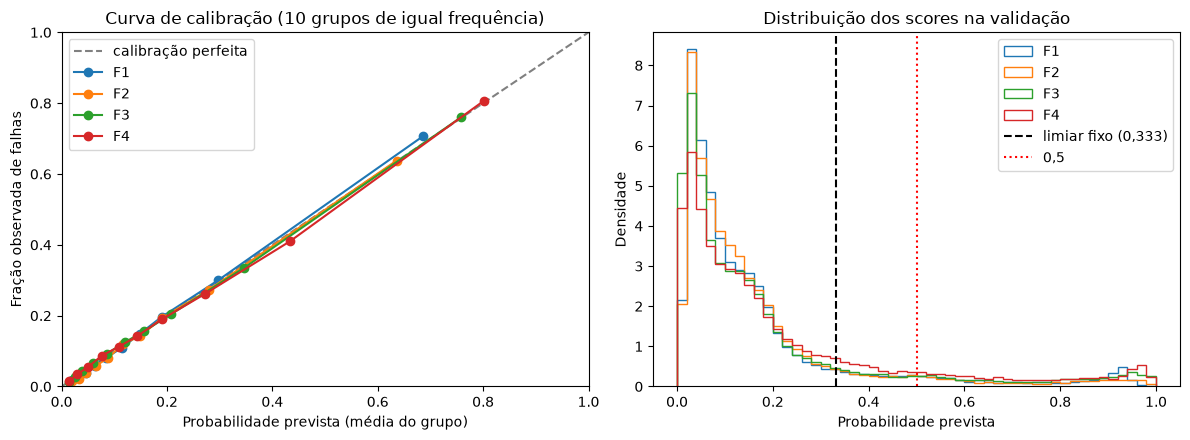

In [25]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))

ax = eixos[0]
ax.plot([0, 1], [0, 1], "--", color="grey", label="calibração perfeita")
for nome, (frac_obs, prob_media) in curvas_cal.items():
    ax.plot(prob_media, frac_obs, "o-", label=nome)
ax.set(xlabel="Probabilidade prevista (média do grupo)", ylabel="Fração observada de falhas",
       title="Curva de calibração (10 grupos de igual frequência)", xlim=(0, 1), ylim=(0, 1))
ax.legend()

ax = eixos[1]
for nome, _, _ in av.FOLDS:
    ax.hist(val_b.loc[val_b["fold"] == nome, "score"], bins=50, range=(0, 1),
            histtype="step", density=True, label=nome)
ax.axvline(LIMIAR_FIXO, color="black", ls="--", label=f"limiar fixo ({LIMIAR_FIXO:.3f})".replace(".", ","))
ax.axvline(0.5, color="red", ls=":", label="0,5")
ax.set(xlabel="Probabilidade prevista", ylabel="Densidade", title="Distribuição dos scores na validação")
ax.legend()

plt.tight_layout()
fig.savefig(PASTA / "task4_calibracao.png", dpi=150)   # para o relatório
plt.show()

**Conclusão.** As probabilidades da Random Forest estão bem calibradas em todos os folds: as curvas seguem a diagonal, o ECE fica entre 0,004 e 0,007, e a probabilidade média prevista fica a menos de 0,005 da prevalência observada, apesar de esta variar entre 15,8 % e 21,1 %. O modelo acompanha, portanto, o nível de risco de cada período, o que é coerente com os históricos do posto refletirem o nível de falhas recente. O Brier skill score, entre 0,27 e 0,33, indica que o modelo reduz o erro de Brier em cerca de 30 % face a prever sempre a prevalência. Perto do limiar fixo complementar (scores entre 0,283 e 0,383), a fração observada de falhas é de 0,318 a 0,339, contra um score médio de 0,327 a 0,329: um score de 0,333 corresponde de facto a cerca de um terço de risco.

**Não se recalibra.** Os alertas do limiar móvel dependem só da ordenação, que uma recalibração monótona não altera, e as probabilidades já estão calibradas.

**Leitura das probabilidades e escolha do limiar.** A distribuição dos scores desloca-se para a direita quando o risco sobe: as sessões perto do limiar fixo são 6,8 % do F4, contra 4,1 % a 4,7 % nos outros folds. É isto que faz um limiar fixo gerar mais alertas nos períodos de mais falhas (secção 9). Como o modelo está calibrado, um limiar fixo mantém constante o significado do alerta (risco de pelo menos um terço), enquanto o limiar móvel mantém constante a carga de trabalho. O critério da secção 8.3 dá prioridade à capacidade de resposta. Os scores de pelo menos 0,5 têm uma fração observada de falhas de cerca de 0,76 (secção 9), coerente com a curva, o que sustenta reservar as ações mais caras para esses alertas.

**Limitações.** Os 10 grupos de igual frequência são largos nos scores altos (o último grupo cobre aproximadamente 0,6 a 1), pelo que a calibração é avaliada com menos detalhe onde há menos sessões. As curvas são da validação; o modelo final é treinado com mais dados, e a sua calibração será confirmada no teste com o Brier e o ECE.